# 1. Linear regression from scratch: predicting diabetes progression

**Question:** can ten routine baseline measurements (age, sex, BMI, blood pressure and six blood-serum readings) predict how far a patient's diabetes will progress one year later?

**Data:** the [diabetes dataset](https://scikit-learn.org/stable/datasets/toy_dataset.html#diabetes-dataset) (Efron et al., 2004): 442 patients, 10 features, target is a quantitative measure of disease progression.

**Approach:** implement multivariate linear regression with batch gradient descent in NumPy (`mlscratch/linear_regression.py`), check it against the closed-form normal equation and scikit-learn, and look at what the model learned.

In [1]:
import sys; sys.path.append('..')
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from mlscratch.linear_regression import (StandardScaler, LinearRegressionGD, normal_equation,
                                         add_bias, r2_score, rmse)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
NAVY = '#1F3864'

## Load and split the data
The test set is held back and never used for training or for fitting the scaler, so the scores below are an honest estimate of performance on new patients.

In [2]:
data = load_diabetes()
X, y = data.data, data.target
feature_names = ['age', 'sex', 'BMI', 'blood pressure', 's1 (cholesterol)', 's2 (LDL)', 's3 (HDL)',
                 's4 (chol/HDL)', 's5 (triglycerides)', 's6 (blood sugar)']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f'Training patients: {len(y_train)}, test patients: {len(y_test)}')

Training patients: 353, test patients: 89


## Feature scaling
Gradient descent converges much faster when features share a scale. The scaler learns the mean and standard deviation from the **training set only**.

In [3]:
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

## Choosing a learning rate
Too small and training crawls; too large and the cost explodes. Comparing a few rates on the cost curve shows the trade-off.

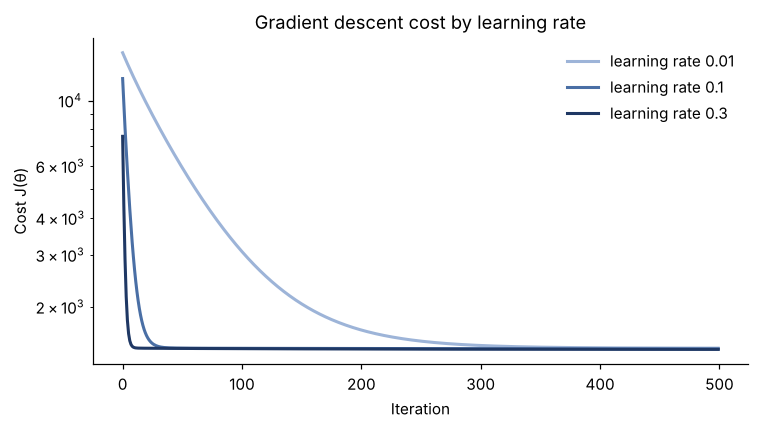

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
for lr, colour in [(0.01, '#9DB4D8'), (0.1, '#4A6FA5'), (0.3, NAVY)]:
    model = LinearRegressionGD(learning_rate=lr, iterations=500).fit(X_train_s, y_train)
    ax.plot(model.cost_history_, label=f'learning rate {lr}', color=colour, linewidth=2)
ax.set_xlabel('Iteration'); ax.set_ylabel('Cost J(θ)'); ax.set_yscale('log')
ax.set_title('Gradient descent cost by learning rate'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig('../images/lr_cost_curves.png', bbox_inches='tight'); plt.show()

## Train and check against the exact solution
Linear regression has a closed-form answer (the normal equation), so we can verify that gradient descent converged to the true optimum, and that it matches scikit-learn.

In [5]:
model = LinearRegressionGD(learning_rate=0.3, iterations=5000).fit(X_train_s, y_train)
theta_exact = normal_equation(add_bias(X_train_s), y_train)
sk = LinearRegression().fit(X_train_s, y_train)

print(f'Largest gap between gradient descent and normal equation weights: {np.abs(model.theta_ - theta_exact).max():.2e}')
y_pred = model.predict(X_test_s)
print(f'From scratch   R² = {r2_score(y_test, y_pred):.3f}   RMSE = {rmse(y_test, y_pred):.1f}')
print(f'scikit-learn   R² = {sk.score(X_test_s, y_test):.3f}')

Largest gap between gradient descent and normal equation weights: 3.94e-05
From scratch   R² = 0.453   RMSE = 53.9
scikit-learn   R² = 0.453


**Why it needed 5,000 iterations:** several blood-serum features are strongly correlated (total cholesterol and LDL move together), which makes the cost surface a long narrow valley. Gradient descent zig-zags down it slowly. The condition number below measures how stretched that valley is.

In [6]:
print(f'Condition number of XᵀX: {np.linalg.cond(X_train_s.T @ X_train_s):.0f}')
print(f'Correlation between s1 and s2: {np.corrcoef(X_train[:, 4], X_train[:, 5])[0, 1]:.2f}')

Condition number of XᵀX: 430
Correlation between s1 and s2: 0.89


## How good are the predictions?

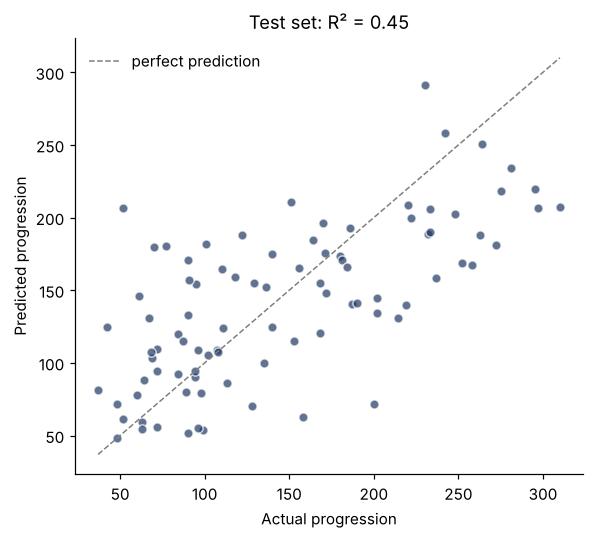

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(y_test, y_pred, color=NAVY, alpha=0.7, edgecolor='white')
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax.plot(lims, lims, '--', color='grey', linewidth=1, label='perfect prediction')
ax.set_xlabel('Actual progression'); ax.set_ylabel('Predicted progression')
ax.set_title(f'Test set: R² = {r2_score(y_test, y_pred):.2f}'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig('../images/predicted_vs_actual.png', bbox_inches='tight'); plt.show()

## What did the model learn?
Because the features are standardised, the weights are comparable: each shows how much predicted progression changes for a one standard deviation increase in that feature, holding the others fixed.

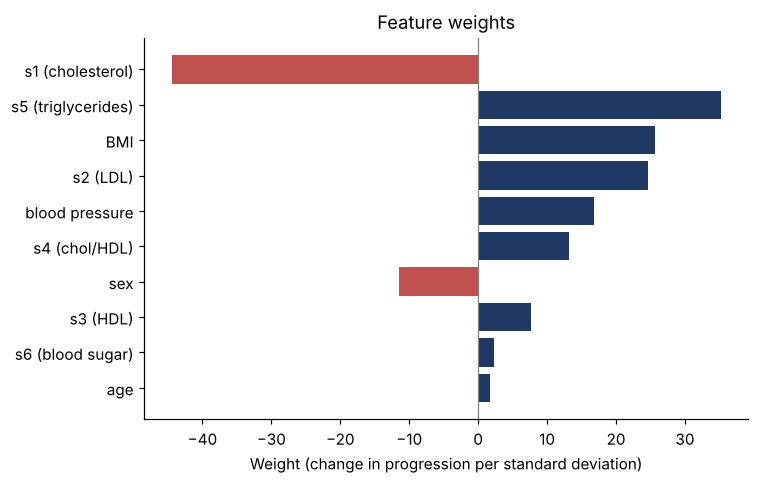

In [8]:
weights = model.theta_[1:]
order = np.argsort(np.abs(weights))
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(np.array(feature_names)[order], weights[order],
        color=[NAVY if w > 0 else '#C0504D' for w in weights[order]])
ax.axvline(0, color='grey', linewidth=0.8)
ax.set_xlabel('Weight (change in progression per standard deviation)')
ax.set_title('Feature weights')
plt.tight_layout(); plt.savefig('../images/feature_weights.png', bbox_inches='tight'); plt.show()

## Findings

- Gradient descent converged to the exact least-squares solution and matches scikit-learn's test R² of about **0.45**.
- **s5 (log triglycerides) and BMI** are the strongest positive predictors, consistent with known metabolic risk factors.
- The single largest weight is on **s1 (total cholesterol), and it's negative**, while s2 (LDL) is strongly positive. That doesn't mean cholesterol protects against diabetes: s1 and s2 are 0.89 correlated, so the model offsets one against the other. This is **multicollinearity**, and it's why weights on correlated features shouldn't be read one at a time.
- An R² of 0.45 means a linear model explains under half the variation. Next steps would be regularisation (ridge) to stabilise the correlated weights, and non-linear models to capture interactions.